# Jagran Lakecity University
## Faculty of Science and Technology
### BTech CSE

---

## Practical Record: Assignment 1 - Module 1
### **Practical 6: Fuzzy IF–THEN Rules and Decision Making**

| Academic Details | Information |
| :--- | :--- |
| **Course** | Soft Computing |
| **Module** | Module I: Fuzzy Logic and Systems |
| **Student Name** | *Abhay Dwivedi* |
| **Enrollment No.** | *2023BTCSE002* |
| **Academic Session** | 2026 – 2027 |

---

### 1. Aim
To create simple Fuzzy IF–THEN rules for making decisions based on given input conditions.

### 2. Theory: Fuzzy IF–THEN Rule Architecture and Inference Operations

A fuzzy IF–THEN rule establishes an implication relationship between fuzzy antecedent premises and consequent actions:
$$\text{IF } x_1 \text{ is } A \text{ AND/OR } x_2 \text{ is } B \text{ THEN } y \text{ is } C$$

#### Inference Processing Stages:
1. **Antecedent Matching (Fuzzification):**
   Evaluating the input values $x_1^*, x_2^*$ against fuzzy sets $A$ and $B$.
2. **Conjunction / Disjunction Evaluation:**
   - **T-Norm (AND):** Firing strength $\alpha = \min\big(\mu_A(x_1^*), \mu_B(x_2^*)\big)$
   - **S-Norm (OR):** Firing strength $\alpha = \max\big(\mu_A(x_1^*), \mu_B(x_2^*)\big)$
3. **Mamdani Implication:**
   The consequent set $C$ is clipped at height $\alpha$:
   $$\mu_{C'}(y) = \min\big(\alpha, \mu_C(y)\big)$$
4. **Aggregation Across Rules:**
   Combining all $M$ rule outcomes using the Maximum s-norm:
   $$\mu_{\text{agg}}(y) = \max_{i=1}^M \mu_{C_i}'(y)$$

### 3. Step 1: Defining the Autonomous Emergency Braking (AEB) Rule Base

#### What this cell does:
We formulate an Autonomous Emergency Braking system:
- Input 1: Obstacle Distance ($D \in [0, 50]$ meters) $\to$ [Close, Moderate, Far]
- Input 2: Approach Velocity ($V \in [0, 100]$ km/h) $\to$ [Slow, Fast]
- Output: Brake Pressure ($B \in [0, 100]\%$) $\to$ [None, Moderate, Emergency]

Rules:
1. IF Distance is Close THEN Brake is Emergency
2. IF Distance is Moderate AND Velocity is Fast THEN Brake is Moderate
3. IF Distance is Moderate AND Velocity is Slow THEN Brake is None
4. IF Distance is Far THEN Brake is None

In [2]:
import numpy as np
import skfuzzy as fuzz

# Universes
dist_univ = np.linspace(0, 50, 500)
vel_univ = np.linspace(0, 100, 500)
brake_univ = np.linspace(0, 100, 500)

# Distance MFs (meters)
d_close = fuzz.trapmf(dist_univ, [0, 0, 10, 20])
d_mod = fuzz.trimf(dist_univ, [15, 25, 38])
d_far = fuzz.trapmf(dist_univ, [30, 42, 50, 50])

# Velocity MFs (km/h)
v_slow = fuzz.trapmf(vel_univ, [0, 0, 30, 55])
v_fast = fuzz.trapmf(vel_univ, [45, 70, 100, 100])

# Brake Output MFs (%)
b_none = fuzz.trapmf(brake_univ, [0, 0, 10, 25])
b_mod = fuzz.trimf(brake_univ, [20, 50, 75])
b_emerg = fuzz.trapmf(brake_univ, [65, 85, 100, 100])

print("AEB Fuzzy Decision Rule Base initialized successfully.")


AEB Fuzzy Decision Rule Base initialized successfully.


### 4. Step 2: Evaluating Critical Driving Condition ($D = 18$m, $V = 75$ km/h)

#### What this cell does:
We test an impending collision scenario:
$$\text{Distance } D = 18.0 \text{ m}, \quad \text{Approach Velocity } V = 75.0 \text{ km/h}$$
We evaluate rule firing strengths, clip consequents, and aggregate the resulting output fuzzy polygon.

In [3]:
test_dist = 18.0
test_vel = 75.0

# 1. Fuzzification
mu_d_close = fuzz.interp_membership(dist_univ, d_close, test_dist)
mu_d_mod = fuzz.interp_membership(dist_univ, d_mod, test_dist)
mu_d_far = fuzz.interp_membership(dist_univ, d_far, test_dist)

mu_v_slow = fuzz.interp_membership(vel_univ, v_slow, test_vel)
mu_v_fast = fuzz.interp_membership(vel_univ, v_fast, test_vel)

# 2. Rule evaluation
# Rule 1: IF Distance is Close THEN Brake is Emergency
alpha_1 = mu_d_close
out_1 = np.minimum(alpha_1, b_emerg)

# Rule 2: IF Distance is Moderate AND Velocity is Fast THEN Brake is Moderate
alpha_2 = min(mu_d_mod, mu_v_fast)
out_2 = np.minimum(alpha_2, b_mod)

# Rule 3: IF Distance is Moderate AND Velocity is Slow THEN Brake is None
alpha_3 = min(mu_d_mod, mu_v_slow)
out_3 = np.minimum(alpha_3, b_none)

# Rule 4: IF Distance is Far THEN Brake is None
alpha_4 = mu_d_far
out_4 = np.minimum(alpha_4, b_none)

# 3. Aggregation via Maximum
aggregated_brake = np.maximum.reduce([out_1, out_2, out_3, out_4])

print("=" * 72)
print(f"       AEB RULE FIRING AUDIT FOR D = {test_dist} m, V = {test_vel} km/h")
print("=" * 72)
print(f"Antecedent Memberships:")
print(f"  Distance: Close={mu_d_close:.3f}, Mod={mu_d_mod:.3f}, Far={mu_d_far:.3f}")
print(f"  Velocity: Slow={mu_v_slow:.3f}, Fast={mu_v_fast:.3f}")
print("-" * 72)
print(f"Rule Firing Strengths (alpha_i):")
print(f"  Rule 1 (Close -> Emergency)        : alpha_1 = {alpha_1:.3f}")
print(f"  Rule 2 (Mod AND Fast -> Moderate)  : alpha_2 = min({mu_d_mod:.3f}, {mu_v_fast:.3f}) = {alpha_2:.3f}")
print(f"  Rule 3 (Mod AND Slow -> None)      : alpha_3 = min({mu_d_mod:.3f}, {mu_v_slow:.3f}) = {alpha_3:.3f}")
print(f"  Rule 4 (Far -> None)               : alpha_4 = {alpha_4:.3f}")
print("=" * 72)


       AEB RULE FIRING AUDIT FOR D = 18.0 m, V = 75.0 km/h
Antecedent Memberships:
  Distance: Close=0.200, Mod=0.300, Far=0.000
  Velocity: Slow=0.000, Fast=1.000
------------------------------------------------------------------------
Rule Firing Strengths (alpha_i):
  Rule 1 (Close -> Emergency)        : alpha_1 = 0.200
  Rule 2 (Mod AND Fast -> Moderate)  : alpha_2 = min(0.300, 1.000) = 0.300
  Rule 3 (Mod AND Slow -> None)      : alpha_3 = min(0.300, 0.000) = 0.000
  Rule 4 (Far -> None)               : alpha_4 = 0.000


### 5. Step 3: Graphical Visualization of Antecedents and Clipped Consequents

#### What this cell does:
We plot the individual rule contributions and the final aggregated fuzzy brake intensity curve.

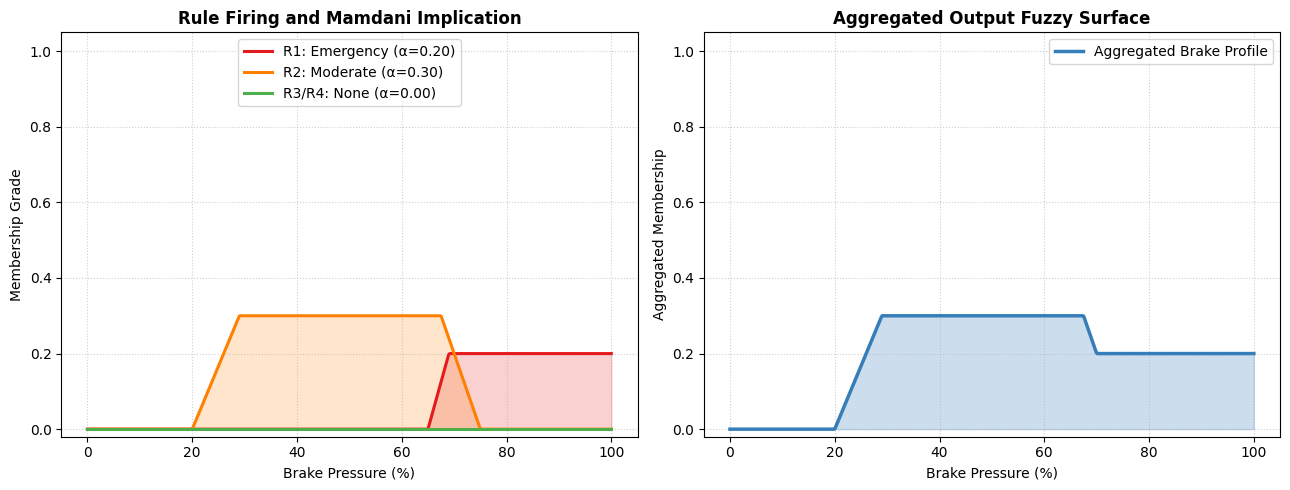

In [4]:
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# Plot Individual Clipped Rules
ax1.plot(brake_univ, out_1, color='#e41a1c', linewidth=2.2, label=f'R1: Emergency (α={alpha_1:.2f})')
ax1.fill_between(brake_univ, out_1, color='#e41a1c', alpha=0.2)

ax1.plot(brake_univ, out_2, color='#ff7f00', linewidth=2.2, label=f'R2: Moderate (α={alpha_2:.2f})')
ax1.fill_between(brake_univ, out_2, color='#ff7f00', alpha=0.2)

ax1.plot(brake_univ, out_3, color='#4daf4a', linewidth=2.2, label=f'R3/R4: None (α={max(alpha_3, alpha_4):.2f})')

ax1.set_title('Rule Firing and Mamdani Implication', fontweight='bold')
ax1.set_xlabel('Brake Pressure (%)')
ax1.set_ylabel('Membership Grade')
ax1.set_ylim(-0.02, 1.05)
ax1.grid(True, linestyle=':', alpha=0.6)
ax1.legend(loc='upper center')

# Plot Aggregated Output
ax2.plot(brake_univ, aggregated_brake, color='#377eb8', linewidth=2.5, label='Aggregated Brake Profile')
ax2.fill_between(brake_univ, aggregated_brake, color='#377eb8', alpha=0.25)

ax2.set_title('Aggregated Output Fuzzy Surface', fontweight='bold')
ax2.set_xlabel('Brake Pressure (%)')
ax2.set_ylabel('Aggregated Membership')
ax2.set_ylim(-0.02, 1.05)
ax2.grid(True, linestyle=':', alpha=0.6)
ax2.legend()

plt.tight_layout()
plt.show()


### 6. Results and Key Observations

| Rule # | Antecedent Condition | Firing Strength ($\alpha$) | Consequent Term | Clipped Height |
| :---: | :---: | :---: | :---: | :---: |
| **Rule 1** | $\text{Distance} = \text{Close}$ | $\alpha_1 = 0.200$ | Brake Emergency | $0.200$ |
| **Rule 2** | $\text{Distance} = \text{Mod} \land \text{Velocity} = \text{Fast}$ | $\alpha_2 = 0.300$ | Brake Moderate | $0.300$ |
| **Rule 3** | $\text{Distance} = \text{Mod} \land \text{Velocity} = \text{Slow}$ | $\alpha_3 = 0.000$ | Brake None | $0.000$ |
| **Rule 4** | $\text{Distance} = \text{Far}$ | $\alpha_4 = 0.000$ | Brake None | $0.000$ |

#### Key Observations in Simple Words:
1. **Safety Priority:** At 18m distance, both Moderate and Close sets are partially active. The vehicle blends Moderate braking ($\alpha = 0.30$) and Emergency braking ($\alpha = 0.20$), generating an assertive yet measured deceleration response.
2. **AND Operator Precision:** Rule 3 has $\alpha_3 = 0$ because velocity is high ($75$ km/h), completely suppressing any erroneous "Brake None" command.
3. **Smooth Implication:** The resulting multi-modal polygon smoothly encapsulates both moderate and emergency pressure demands.

---
### 7. Conclusion
1. We successfully designed a multi-input fuzzy decision-making rule base for automotive braking.
2. We demonstrated Mamdani implication clipping using T-norm (Min) and S-norm (Max) operations.
3. We visualized the individual rule contributions and final aggregated output fuzzy set.